<a href="https://colab.research.google.com/github/1BF24CS033/BIS/blob/main/Particle_Swarm_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

np.random.seed(42)

processing_times = [12, 8, 17, 5, 15, 13]
num_jobs = len(processing_times)

num_particles = 6
max_iterations = 1000
w = 0.7       # Inertia weight
c1 = 1.5      # Cognitive component
c2 = 1.5      # Social component

positions = np.random.uniform(-2.0, 2.0, (num_particles, num_jobs))
velocities = np.zeros((num_particles, num_jobs))

def decode_spv(position):
    job_order = np.argsort(position)
    current_time = 0
    total_completion_time = 0

    for job_idx in job_order:
        current_time += processing_times[job_idx]
        total_completion_time += current_time

    return job_order, total_completion_time

pbest_positions = np.copy(positions)
pbest_fitness = np.zeros(num_particles)

for i in range(num_particles):
    _, pbest_fitness[i] = decode_spv(positions[i])

gbest_idx = np.argmin(pbest_fitness)
gbest_position = np.copy(pbest_positions[gbest_idx])
gbest_fitness = pbest_fitness[gbest_idx]

print("==================== INITIAL STATE ====================")
print(f"Initial Best Fitness: {gbest_fitness} (Schedule: {list(np.argsort(gbest_position))})")

for iteration in range(1, max_iterations + 1):
    r1 = np.random.rand(num_particles, num_jobs)
    r2 = np.random.rand(num_particles, num_jobs)

    velocities = (w * velocities +
                  c1 * r1 * (pbest_positions - positions) +
                  c2 * r2 * (gbest_position - positions))

    positions = positions + velocities
    improved = False

    for i in range(num_particles):
        job_order, fitness = decode_spv(positions[i])

        if fitness < pbest_fitness[i]:
            pbest_fitness[i] = fitness
            pbest_positions[i] = np.copy(positions[i])

            if fitness < gbest_fitness:
                gbest_fitness = fitness
                gbest_position = np.copy(positions[i])
                improved = True

    if improved:
        print(f"Iteration {iteration:03d}/{max_iterations}: New Global Best: {gbest_fitness} | Schedule: {list(np.argsort(gbest_position))}")
    elif iteration % 50 == 0:
        print(f"Iteration {iteration:03d}/{max_iterations}: Current Best: {gbest_fitness}")

best_schedule = list(np.argsort(gbest_position))
print("\n==================== FINAL RESULTS ====================")
print(f"Optimal Job Sequence: {best_schedule}")
print(f"Optimal Total Completion Time: {gbest_fitness}")

==================== INITIAL STATE ====================
Initial Best Fitness: 210.0 (Schedule: [np.int64(3), np.int64(1), np.int64(4), np.int64(5), np.int64(0), np.int64(2)])
Iteration 001/1000: New Global Best: 208 | Schedule: [np.int64(3), np.int64(1), np.int64(5), np.int64(4), np.int64(0), np.int64(2)]
Iteration 006/1000: New Global Best: 205 | Schedule: [np.int64(3), np.int64(1), np.int64(5), np.int64(0), np.int64(4), np.int64(2)]
Iteration 007/1000: New Global Best: 204 | Schedule: [np.int64(3), np.int64(1), np.int64(0), np.int64(5), np.int64(4), np.int64(2)]
Iteration 050/1000: Current Best: 204
Iteration 100/1000: Current Best: 204
Iteration 150/1000: Current Best: 204
Iteration 200/1000: Current Best: 204
Iteration 250/1000: Current Best: 204
Iteration 300/1000: Current Best: 204
Iteration 350/1000: Current Best: 204
Iteration 400/1000: Current Best: 204
Iteration 450/1000: Current Best: 204
Iteration 500/1000: Current Best: 204
Iteration 550/1000: Current Best: 204
Iteration 6

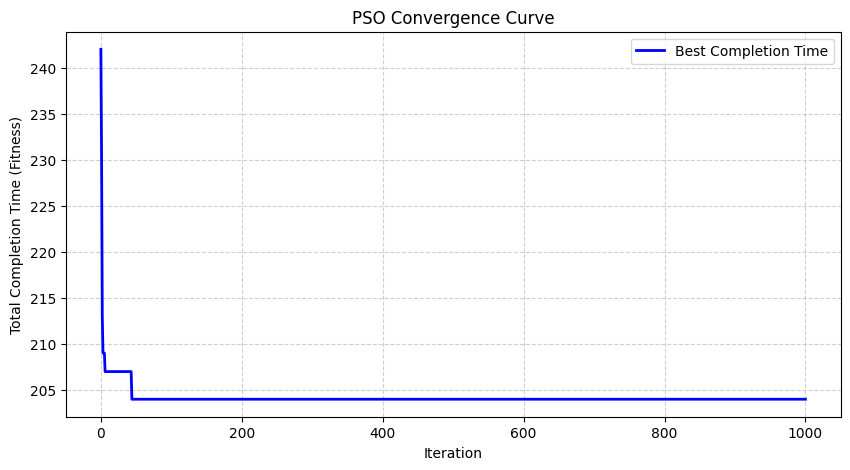

In [ ]:
import matplotlib.pyplot as plt

# Reset random seed for reproducibility
np.random.seed(42)

# Initialize particles
positions = np.random.uniform(-2.0, 2.0, (num_particles, num_jobs))
velocities = np.zeros((num_particles, num_jobs))
pbest_positions = np.copy(positions)
pbest_fitness = np.zeros(num_particles)

for i in range(num_particles):
    _, pbest_fitness[i] = decode_spv(positions[i])

gbest_idx = np.argmin(pbest_fitness)
gbest_position = np.copy(pbest_positions[gbest_idx])
gbest_fitness = pbest_fitness[gbest_idx]

# List to keep track of the best fitness at each iteration for plotting
fitness_history = [gbest_fitness]

for iteration in range(1, max_iterations + 1):
    r1 = np.random.rand(num_particles, num_jobs)
    r2 = np.random.rand(num_particles, num_jobs)

    velocities = (w * velocities +
                  c1 * r1 * (pbest_positions - positions) +
                  c2 * r2 * (gbest_position - positions))

    positions = positions + velocities

    for i in range(num_particles):
        job_order, fitness = decode_spv(positions[i])

        if fitness < pbest_fitness[i]:
            pbest_fitness[i] = fitness
            pbest_positions[i] = np.copy(positions[i])

            if fitness < gbest_fitness:
                gbest_fitness = fitness
                gbest_position = np.copy(positions[i])

    fitness_history.append(gbest_fitness)

# Plotting the convergence curve
plt.figure(figsize=(10, 5))
plt.plot(range(0, max_iterations + 1), fitness_history, color='blue', linewidth=2, label='Best Completion Time')
plt.title('PSO Convergence Curve')
plt.xlabel('Iteration')
plt.ylabel('Total Completion Time (Fitness)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### Parameters You Can Adjust to Get Different Results

To explore how the Particle Swarm Optimization (PSO) behaves, you can modify the following sets of parameters in the code above:

#### 1. Problem Definition (The Inputs)
If you change these, you are solving an entirely different scheduling problem:
* **`processing_times`**: Currently `[12, 8, 20, 5, 15]`. Changing these numbers (or adding more jobs) will change the optimal sequence and the minimum completion time.
* **`np.random.seed(42)`**: Changing the seed (e.g., to `100`, or removing it) will generate a different initial set of random positions for the particles, leading to different search paths.

#### 2. Swarm Size and Iterations
* **`num_particles`** (Currently `3`): A larger swarm (e.g., `10` or `20` particles) covers more search space and is much more likely to find the optimal schedule faster, though it takes more calculations per iteration.
* **`max_iterations`** (Currently `1000`): If you increase the number of particles, you can often decrease the max iterations because the swarm converges much quicker.

#### 3. PSO Hyperparameters (The Motion Weights)
These control how the particles move through the search space:
* **`w` (Inertia Weight, currently `0.7`)**: Controls how much of the previous velocity is kept.
  * A *higher* `w` (e.g., `0.9`) encourages exploration (searching new areas).
  * A *lower* `w` (e.g., `0.4`) encourages exploitation (converging quickly around known good areas).
* **`c1` (Cognitive Coefficient, currently `1.5`)**: Determines how strongly a particle is pulled toward its *own historical best* position.
* **`c2` (Social Coefficient, currently `1.5`)**: Determines how strongly a particle is pulled toward the *global best* position found by the entire swarm.